In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# 1. Load the Titanic Dataset directly via URL
file = "Clean_Titanic.csv"
df = pd.read_csv(file)

# 2. Select relevant features for clustering
# We omit Name, PassengerId, Ticket, and Cabin as they are unique identifiers
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X = df[features].copy()

# 3. Handle Missing Values
X['Age'] = X['Age'].fillna(X['Age'].median())  # Fill missing ages with the median age

# 4. Convert Categorical Text ('Sex') into numerical formatting
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})

# 5. Feature Scaling (Crucial for distance-based models like K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. Initialize and Fit K-Means
# We choose 2 clusters to see if the algorithm separates passengers into distinct groups
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 7. Evaluate the Clusters against actual Survival rates
print("--- Cluster Profiles & Metrics ---")
cluster_summary = df.groupby('Cluster').agg({
    'Survived': 'mean',  # Survival rate per cluster
    'Age': 'mean',       # Average age per cluster
    'Fare': 'mean',      # Average ticket price per cluster
    'Pclass': 'mean',    # Average passenger class per cluster
    'PassengerId': 'count' # Number of passengers in each cluster
}).rename(columns={'PassengerId': 'Passenger Count'})

print(cluster_summary.to_string())


--- Cluster Profiles & Metrics ---
         Survived        Age       Fare    Pclass  Passenger Count
Cluster                                                           
0        0.297972  25.086538  15.281064  2.765991              641
1        0.604000  40.056455  75.595150  1.136000              250


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

file = "Clean_Health.csv"
df = pd.read_csv(file)


features = [
    "Age",
    "Billing Amount",
    "New_Gender",
    "Admission Type",
    "Length of Stay",
    "Medical Condition",
    "Medication",
    "Test Results"
]
X = df[features].copy()

# X['Age'] = X['Age'].fillna(X['Age'].median())

# X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("--- Cluster Profiles & Metrics ---")

cluster_summary = df.groupby('Cluster').agg({
    'Survived': 'mean',
    'Age': 'mean',
    'Fare': 'mean',
    'Pclass': 'mean',
    'PassengerId': 'count'
}).rename(columns={'PassengerId': 'Passenger Count'})

print(cluster_summary.to_string())

In [2]:
import pandas as pd
df = pd.read_csv("Clean_Health.csv")
df.columns.tolist()

['Name',
 'Age',
 'Gender',
 'Blood Type',
 'Medical Condition',
 'Date of Admission',
 'Doctor',
 'Hospital',
 'Insurance Provider',
 'Billing Amount',
 'Room Number',
 'Admission Type',
 'Discharge Date',
 'Medication',
 'Test Results',
 'New_Gender']

Silhouette Score :  0.4028471317296809


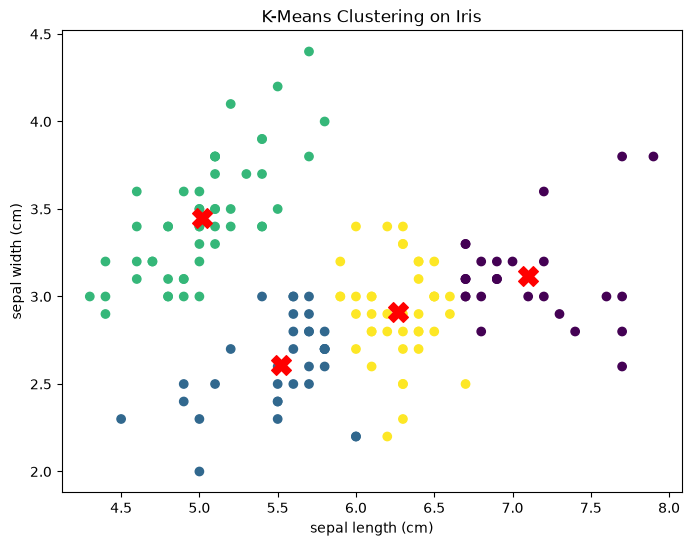

In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

iris = load_iris()
X = iris.data[:, :2]

kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(X)

print("Silhouette Score : " , silhouette_score(X ,labels))

plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=labels, cmap="viridis")
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c="red",
    marker="X",
    s=200
)
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("K-Means Clustering on Iris")
plt.show()

In [2]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

iris = load_iris()

X = iris.data

kmeans = KMeans(n_clusters=3, random_state=42)

labels = kmeans.fit_predict(X)

print("Silhouette Score:", silhouette_score(X, labels))

Silhouette Score: 0.551191604619592


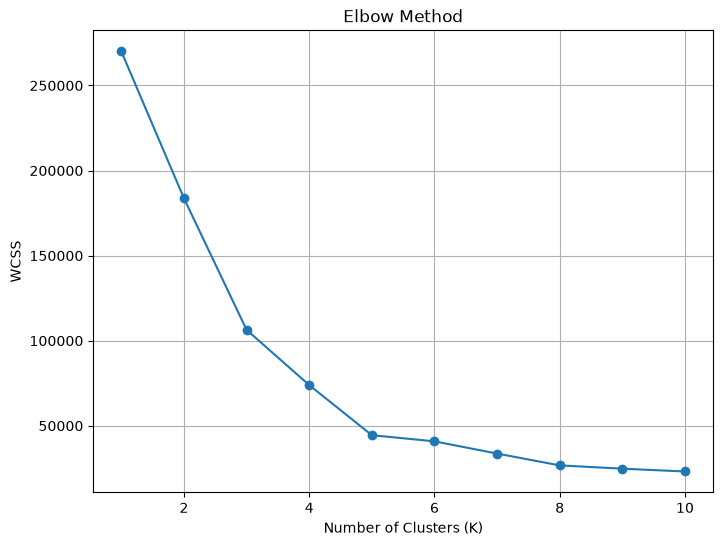

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

df = pd.read_csv("Mall.csv")

X = df[['Annual_Income', 'Spending_Score']]

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

Silhouette Score: 0.3868530059780521


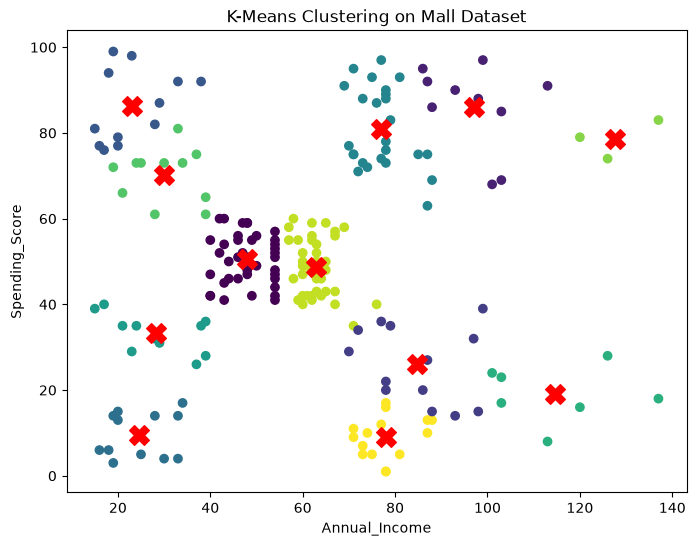

In [29]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# iris = load_iris()
df = pd.read_csv("Mall.csv")
# X = iris.data[:, :2]


le = LabelEncoder()

#df['Genre'] = le.fit_transform(df['Genre'])
#if "CustomerID" in df.columns:
df = df.drop(["CustomerID", "Age","Genre"], axis=1)
X = df.values

kmeans = KMeans(n_clusters=12, random_state=42)

labels = kmeans.fit_predict(X)

print("Silhouette Score:", silhouette_score(X, labels))

plt.figure(figsize=(8,6))

plt.scatter(
    X[:,0],
    X[:,1],
    c=labels,
    cmap="viridis"
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c="red",
    marker="X",
    s=200
)

plt.xlabel(df.columns[0])
plt.ylabel(df.columns[1])
plt.title("K-Means Clustering on Mall Dataset")

plt.show()